<a href="https://colab.research.google.com/github/Fawwaz-05/data-science-toolkit2/blob/main/Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [67]:
 from google.colab import userdata

 !mkdir -p ~/.kaggle && echo '{{"username":"{userdata.get("kaggle_username")}","key":"{userdata.get("kaggle_token")}"}}' > ~/.kaggle/kaggle.json && chmod 600 ~/.kaggle/kaggle.json


In [64]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

cp: cannot stat 'kaggle.json': No such file or directory


In [45]:
ls -ltr ~/.kaggle/

total 4
-rw------- 1 root root 44 Oct 24 12:08 access_token


In [66]:
 !kaggle datasets list

ref                                                  title                                                    size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------  -------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
dmitriigluzdov/casmi26-pubchem-popularity-prior      CASMI26 PubChem Popularity Prior                            0  2026-10-20 18:37:28.643000          26994         90                1  
nartaa/rsna-knee-publication-swa-weights-20261007    RSNA Knee selected SWA weights 0949 and 0945        543312838  2026-10-07 19:26:38.967000           6139         30            0.625  
heliosli/rsna-orthofoundation-fold0-epoch7-20261004  RSNA OrthoFoundation Fold0 Epoch7 Private Weights  1343091054  2026-10-04 07:54:46.543000          57672         25            0.625  
seyitkaangunes/ntl-extra-api-passages                Name Th

In [7]:
!kaggle datasets download -d 'nasasiratomowen/student-habits-performance-csv' -p ../data/KaggleDataSet

Dataset URL: https://www.kaggle.com/datasets/nasasiratomowen/student-habits-performance-csv
License(s): CC0-1.0
100% 19.1k/19.1k [00:00<00:00, 58.4MB/s]



In [8]:
ls -ltr ../data/KaggleDataSet/

total 20
-rw-r--r-- 1 root root 19512 May 23  2025 student-habits-performance-csv.zip


In [9]:
# Force a clean install of the latest version without dependency conflicts
!pip install --upgrade --force-reinstall --no-deps kaggle


  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [10]:
!unzip ../data/KaggleDataSet/student-habits-performance-csv.zip -d ../data/KaggleDataSet/


Archive:  ../data/KaggleDataSet/student-habits-performance-csv.zip
  inflating: ../data/KaggleDataSet/student_habits_performance.csv  


In [11]:
!chmod 777 ../data/KaggleDataSet/student_habits_performance.csv

In [12]:
#Question 1


import pandas as pd

df = pd.read_csv('../data/KaggleDataSet/student_habits_performance.csv')
df.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [13]:
#Question 2
#THE DATA IS GOOD IT HAVE GOOD AMOUNT OF SAMPLES


print("Row and colums : ", df.shape)
print("Student_id repeated:", df["student_id"].duplicated().sum())
print("Gender distribution:")
print(df["gender"].value_counts())


Row and colums :  (1000, 16)
Student_id repeated: 0
Gender distribution:
gender
Female    481
Male      477
Other      42
Name: count, dtype: int64


In [17]:
#QUESTION 3

print("All columns:")
print(df.columns.tolist())
print("Number of columns:", len(df.columns))
print("Possible input columns (excluding Survived):", len(df.columns) - 1)


All columns:
['student_id', 'age', 'gender', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'part_time_job', 'attendance_percentage', 'sleep_hours', 'diet_quality', 'exercise_frequency', 'parental_education_level', 'internet_quality', 'mental_health_rating', 'extracurricular_participation', 'exam_score']
Number of columns: 16
Possible input columns (excluding Survived): 15


In [18]:
#QUESTION 4

print("Number of Student:", len(df))


Number of Student: 1000


In [19]:
#QUESTION 5

print(df.dtypes)

student_id                        object
age                                int64
gender                            object
study_hours_per_day              float64
social_media_hours               float64
netflix_hours                    float64
part_time_job                     object
attendance_percentage            float64
sleep_hours                      float64
diet_quality                      object
exercise_frequency                 int64
parental_education_level          object
internet_quality                  object
mental_health_rating               int64
extracurricular_participation     object
exam_score                       float64
dtype: object


In [20]:
#QUESTION 6

missing = df.isnull().sum()
print("Missing values:")
print(missing)
print("\nColumns with any missing values: ")
print(missing[missing > 0])
print("\nNumber of columns with mising values : " , (missing > 0).sum())

Missing values:
student_id                        0
age                               0
gender                            0
study_hours_per_day               0
social_media_hours                0
netflix_hours                     0
part_time_job                     0
attendance_percentage             0
sleep_hours                       0
diet_quality                      0
exercise_frequency                0
parental_education_level         91
internet_quality                  0
mental_health_rating              0
extracurricular_participation     0
exam_score                        0
dtype: int64

Columns with any missing values: 
parental_education_level    91
dtype: int64

NUmber of columns with mising values :  1


In [21]:
#QUESTION 7

rows_missing = df[df.isnull().any(axis=1)]
print("Number of Rows with at leath one missing value : ", len(rows_missing))
print("First 10 rows containing mising value:")
display(rows_missing.head(10))

Number of Rows with at leath one missing value :  91
First 10 rows containing mising value:


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
10,S1010,19,Female,4.6,3.7,0.8,No,77.6,5.8,Fair,1,NaN,Good,3,No,63.3
33,S1033,18,Female,4.0,0.9,1.1,No,99.5,5.8,Poor,2,NaN,Average,5,No,70.7
47,S1047,23,Female,2.5,2.9,2.7,No,83.5,7.0,Good,4,NaN,Good,8,Yes,59.7
74,S1074,21,Female,2.3,1.0,0.4,No,100.0,6.4,Fair,6,NaN,Good,1,No,66.9
93,S1093,22,Male,4.1,2.5,3.0,No,85.1,5.8,Good,4,NaN,Good,5,No,70.2
100,S1100,23,Male,4.3,3.0,1.5,No,100.0,7.5,Good,5,NaN,Average,10,Yes,93.2
102,S1102,18,Male,4.3,4.0,0.8,No,100.0,7.5,Fair,0,NaN,Average,1,No,60.8
107,S1107,20,Male,2.1,2.9,1.4,No,76.9,6.1,Fair,4,NaN,Average,7,No,60.4
115,S1115,20,Female,3.7,1.2,3.3,No,88.5,7.7,Poor,5,NaN,Good,9,No,82.7
116,S1116,17,Male,7.0,3.3,3.1,No,88.4,6.1,Good,5,NaN,Average,6,Yes,94.8


In [22]:
#QUESTION 8


column_to_check = "parental_education_level"
print("Student Id that have mising value :", column_to_check,":")
print(df[df[column_to_check].isnull()]["student_id"].tolist())


Student Id that have mising value : parental_education_level :
['S1010', 'S1033', 'S1047', 'S1074', 'S1093', 'S1100', 'S1102', 'S1107', 'S1115', 'S1116', 'S1117', 'S1143', 'S1145', 'S1149', 'S1153', 'S1178', 'S1180', 'S1202', 'S1214', 'S1261', 'S1277', 'S1282', 'S1285', 'S1290', 'S1303', 'S1307', 'S1320', 'S1331', 'S1334', 'S1365', 'S1376', 'S1391', 'S1401', 'S1403', 'S1415', 'S1418', 'S1421', 'S1437', 'S1442', 'S1465', 'S1480', 'S1482', 'S1486', 'S1497', 'S1502', 'S1505', 'S1507', 'S1512', 'S1526', 'S1531', 'S1539', 'S1554', 'S1555', 'S1562', 'S1569', 'S1602', 'S1603', 'S1620', 'S1637', 'S1645', 'S1647', 'S1662', 'S1666', 'S1677', 'S1680', 'S1681', 'S1682', 'S1689', 'S1708', 'S1728', 'S1740', 'S1760', 'S1766', 'S1782', 'S1785', 'S1795', 'S1802', 'S1824', 'S1829', 'S1836', 'S1872', 'S1887', 'S1899', 'S1910', 'S1911', 'S1920', 'S1921', 'S1925', 'S1939', 'S1945', 'S1967']


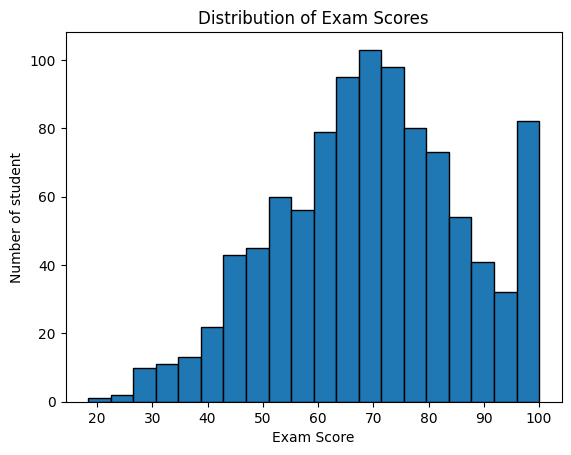

In [14]:



import matplotlib.pyplot as plt

# Corrected the column name to 'exam_score' and switched to a histogram for continuous data
plt.hist(df["exam_score"], bins=20, edgecolor="black")
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of student")
plt.show()


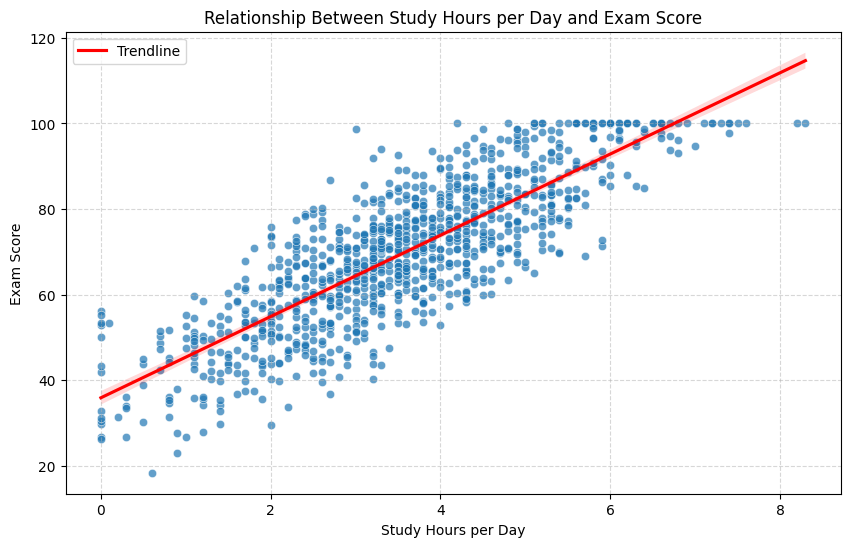

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='study_hours_per_day', y='exam_score', alpha=0.7)
sns.regplot(data=df, x='study_hours_per_day', y='exam_score', scatter=False, color='red', label='Trendline')

plt.title('Relationship Between Study Hours per Day and Exam Score')
plt.xlabel('Study Hours per Day')
plt.ylabel('Exam Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()